<a href="https://colab.research.google.com/github/Monke01/MACHINE-LEARNING-FINAL-PROJECT-/blob/main/Review_1_of_machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

df = pd.read_excel('patients_data_with_alerts.xlsx')

print(f"Dataset Loaded Successfully! Shape: {df.shape}")
df.head()


Dataset Loaded Successfully! Shape: (50000, 13)


,Patient Number,Heart Rate (bpm),SpO2 Level (%),Systolic Blood Pressure (mmHg),Diastolic Blood Pressure (mmHg),Body Temperature (°C),Fall Detection,Predicted Disease,Data Accuracy (%),Heart Rate Alert,SpO2 Level Alert,Blood Pressure Alert,Temperature Alert
0,1,96,92,101,89,36.904680,No,Asthma,95,Normal,Normal,Normal,Normal
1,2,76,83,103,85,37.254129,Yes,Diabetes Mellitus,91,Normal,Low,Normal,Abnormal
2,3,92,88,123,70,36.539418,Yes,Asthma,86,Normal,Low,Normal,Normal
3,4,137,84,167,97,37.018767,Yes,Normal,99,High,Low,High,Normal
4,5,76,81,175,80,37.328671,No,Normal,93,Normal,Low,High,Abnormal


In [ ]:
# 1. Donut Chart - Predicted Disease Breakdown
disease_counts = df['Predicted Disease'].value_counts().reset_index()
disease_counts.columns = ['Predicted Disease', 'Count']

fig1 = px.pie(
    disease_counts,
    values='Count',
    names='Predicted Disease',
    hole=0.4,
    template='plotly_dark',
    color_discrete_sequence=px.colors.qualitative.Pastel,
    title='<b>1. Distribution of Predicted Diseases in Patients</b>'
)
fig1.show()


In [ ]:
# 2. Box Plot - Oxygen (SpO2) Levels by Disease
fig2 = px.box(
    df,
    x='Predicted Disease',
    y='SpO2 Level (%)',
    color='Predicted Disease',
    template='plotly_dark',
    title='<b>2. SpO2 Oxygen Level Distribution by Predicted Disease</b>'
)
fig2.show()


In [ ]:
# 3. Scatter Plot - Blood Pressure Correlation
fig3 = px.scatter(
    df,
    x='Systolic Blood Pressure (mmHg)',
    y='Diastolic Blood Pressure (mmHg)',
    color='Blood Pressure Alert',
    size='Heart Rate (bpm)',
    template='plotly_dark',
    title='<b>3. Systolic vs Diastolic Blood Pressure (Sized by Heart Rate)</b>'
)
fig3.show()


In [ ]:
# 4. Histogram - Body Temperature Distribution
fig4 = px.histogram(
    df,
    x='Body Temperature (°C)',
    color='Temperature Alert',
    barmode='overlay',
    nbins=30,
    template='plotly_dark',
    title='<b>4. Patient Body Temperature Distribution by Temperature Alert</b>'
)
fig4.show()


In [ ]:
# 5. Grouped Bar Chart - Fall Detection by Disease
fall_df = df.groupby(['Predicted Disease', 'Fall Detection']).size().reset_index(name='Patient Count')

fig5 = px.bar(
    fall_df,
    x='Predicted Disease',
    y='Patient Count',
    color='Fall Detection',
    barmode='group',
    template='plotly_dark',
    title='<b>5. Fall Detection Count Grouped by Predicted Disease</b>'
)
fig5.show()


In [ ]:
# =========================
# 6. PREPROCESSING
# =========================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Remove patient ID
X = df.drop(columns=['Predicted Disease', 'Patient Number'], errors='ignore')
y = df['Predicted Disease']

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns

print("Numerical Features:", list(numeric_cols))
print("Categorical Features:", list(categorical_cols))

# Preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', __import__('sklearn').preprocessing.OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Preprocessing completed successfully!")

Numerical Features: ['Heart Rate (bpm)', 'SpO2 Level (%)', 'Systolic Blood Pressure (mmHg)', 'Diastolic Blood Pressure (mmHg)', 'Body Temperature (°C)', 'Data Accuracy (%)']
Categorical Features: ['Fall Detection', 'Heart Rate Alert', 'SpO2 Level Alert', 'Blood Pressure Alert', 'Temperature Alert']
Training samples: 40000
Testing samples: 10000
Preprocessing completed successfully!


In [ ]:
# =========================
# 7. MACHINE LEARNING MODELS
# =========================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel='rbf')
}

trained_models = {}
predictions = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred

    print(f"\n{name}")
    print("Training completed.")
    print("Sample predictions:", y_pred[:5])


Logistic Regression
Training completed.
Sample predictions: ['Normal' 'Normal' 'Hypertension' 'Hypertension' 'Arrhythmia']

Decision Tree
Training completed.
Sample predictions: ['Normal' 'Hypertension' 'Diabetes Mellitus' 'Diabetes Mellitus'
 'Arrhythmia']

Random Forest
Training completed.
Sample predictions: ['Normal' 'Normal' 'Hypertension' 'Hypertension' 'Arrhythmia']

KNN
Training completed.
Sample predictions: ['Normal' 'Normal' 'Hypertension' 'Hypertension' 'Asthma']

SVM
Training completed.
Sample predictions: ['Normal' 'Normal' 'Hypertension' 'Hypertension' 'Arrhythmia']


In [ ]:
# =========================
# 8. PERFORMANCE ANALYSIS
# =========================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import pandas as pd

results = []

for name, y_pred in predictions.items():

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='weighted', zero_division=0),
        "Recall": recall_score(y_test, y_pred, average='weighted', zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, average='weighted', zero_division=0)
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8469,0.8476,0.8469,0.8472
1,Decision Tree,0.7042,0.7039,0.7042,0.7040
2,Random Forest,0.7894,0.7912,0.7894,0.7901
3,KNN,0.7376,0.7402,0.7376,0.7386
4,SVM,0.8444,0.8457,0.8444,0.8449


In [ ]:
# =========================
# 9. MODEL COMPARISON GRAPH
# =========================

import plotly.express as px

metrics_df = results_df.melt(
    id_vars='Algorithm',
    value_vars=['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)

fig = px.bar(
    metrics_df,
    x='Algorithm',
    y='Score',
    color='Metric',
    barmode='group',
    title='Comparison of Machine Learning Algorithms',
    text_auto='.2f'
)

fig.update_yaxes(range=[0, 1])
fig.show()

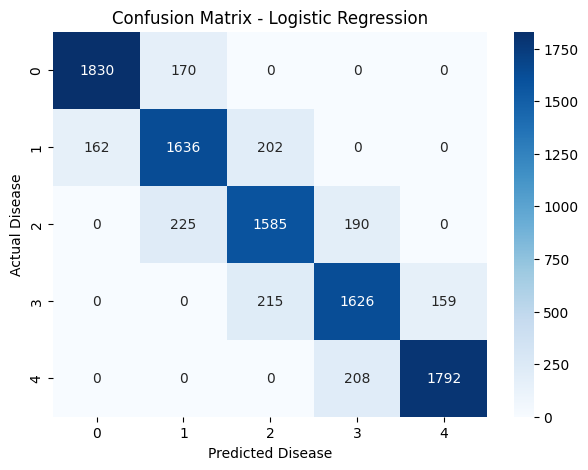

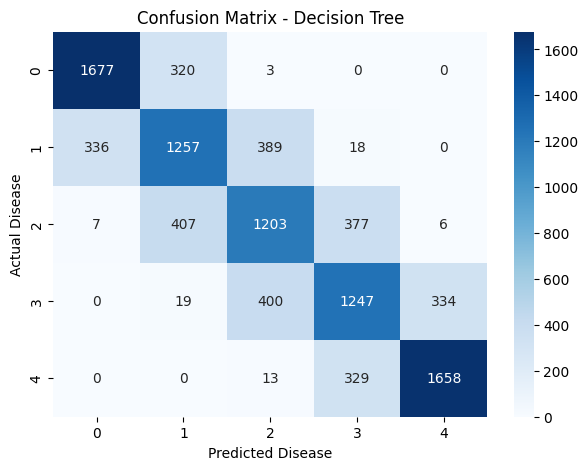

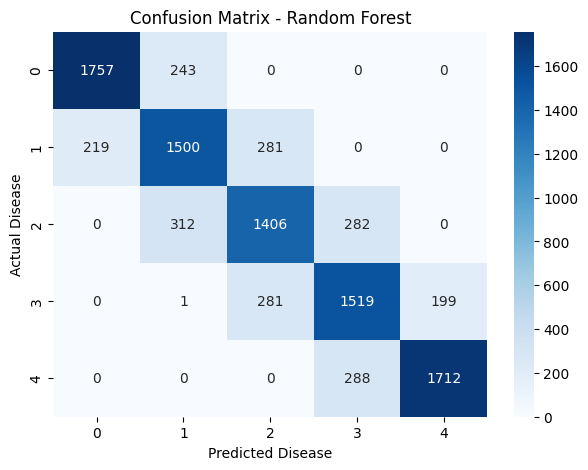

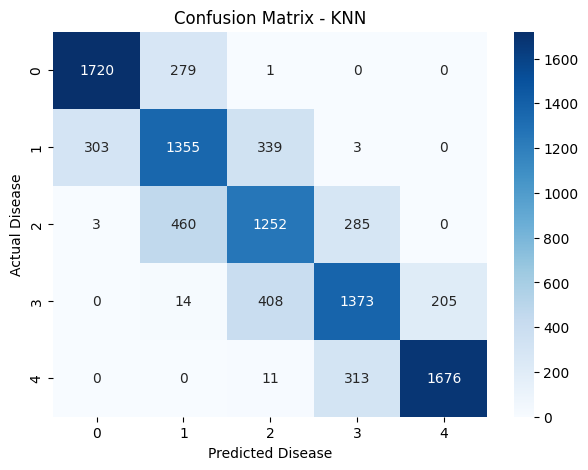

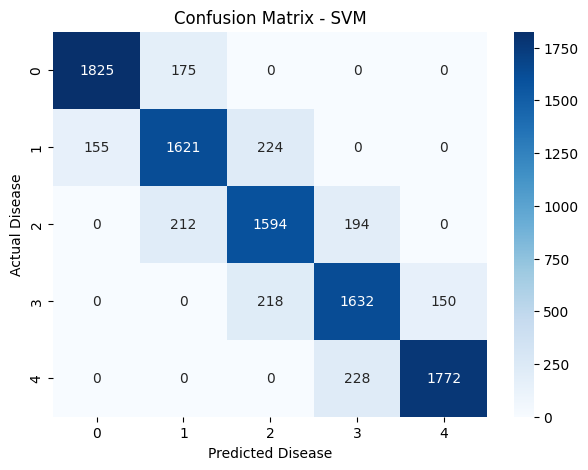

In [ ]:
# =========================
# 10. CONFUSION MATRICES
# =========================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Disease')
    plt.ylabel('Actual Disease')
    plt.show()

In [ ]:
# =========================
# 11. CLASSIFICATION REPORTS
# =========================

for name, y_pred in predictions.items():

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

Logistic Regression
                   precision    recall  f1-score   support

       Arrhythmia       0.92      0.92      0.92      2000
           Asthma       0.81      0.82      0.81      2000
Diabetes Mellitus       0.79      0.79      0.79      2000
     Hypertension       0.80      0.81      0.81      2000
           Normal       0.92      0.90      0.91      2000

         accuracy                           0.85     10000
        macro avg       0.85      0.85      0.85     10000
     weighted avg       0.85      0.85      0.85     10000

Decision Tree
                   precision    recall  f1-score   support

       Arrhythmia       0.83      0.84      0.83      2000
           Asthma       0.63      0.63      0.63      2000
Diabetes Mellitus       0.60      0.60      0.60      2000
     Hypertension       0.63      0.62      0.63      2000
           Normal       0.83      0.83      0.83      2000

         accuracy                           0.70     10000
        macro avg

In [ ]:
# =========================
# 12. SAMPLE INPUT & OUTPUT
# =========================

sample = X_test.iloc[[0]]

print("INPUT PATIENT DATA")
display(sample)

print("\nMODEL PREDICTIONS")
print("=" * 50)

for name, model in trained_models.items():

    prediction = model.predict(sample)[0]

    print(f"{name}: {prediction}")

INPUT PATIENT DATA


,Heart Rate (bpm),SpO2 Level (%),Systolic Blood Pressure (mmHg),Diastolic Blood Pressure (mmHg),Body Temperature (°C),Fall Detection,Data Accuracy (%),Heart Rate Alert,SpO2 Level Alert,Blood Pressure Alert,Temperature Alert
35514,130,88,150,98,37.250209,Yes,90,High,Low,High,Abnormal



MODEL PREDICTIONS
Logistic Regression: Normal
Decision Tree: Normal
Random Forest: Normal
KNN: Normal
SVM: Normal


In [ ]:
# =========================
# 14. FINAL RESULT
# =========================

best_row = results_df.loc[results_df['F1 Score'].idxmax()]

print("FINAL RESULT")
print("=" * 50)
print(f"Best Algorithm : {best_row['Algorithm']}")
print(f"Accuracy       : {best_row['Accuracy']:.2%}")
print(f"Precision      : {best_row['Precision']:.2%}")
print(f"Recall         : {best_row['Recall']:.2%}")
print(f"F1 Score       : {best_row['F1 Score']:.2%}")

print("\nConclusion:")
print(
    f"{best_row['Algorithm']} achieved the best overall performance "
    f"based on the F1 Score among the implemented algorithms."
)

FINAL RESULT
Best Algorithm : Logistic Regression
Accuracy       : 84.69%
Precision      : 84.76%
Recall         : 84.69%
F1 Score       : 84.72%

Conclusion:
Logistic Regression achieved the best overall performance based on the F1 Score among the implemented algorithms.
